# Order-Failure Root Cause: which orders fail, and why?

**Problem.** 8.6% of resolved Olist orders fail: 8.1% arrive after the promised date and 0.5% are cancelled. A dashboard shows *that* the rate moves. It doesn't show *where* failures concentrate, or whether a spike is one bad segment or a network-wide problem.

**Approach.**
1. Build one row per order with 16 attributes known at purchase time.
2. Run a **breadth-first search over attribute combinations**, up to 3 conditions.
3. Test every segment against the rest of the orders with a two-proportion z-test, corrected with **Benjamini–Hochberg** for the ~12K tests.
4. Keep a combination only if it beats each of its sub-segments, so it's a real interaction.
5. Rank by **excess failures** and de-duplicate overlapping segments.

Full repo with tests and a CLI: [github.com/tima-chan/order-failure-root-cause](https://github.com/tima-chan/order-failure-root-cause)

In [1]:
from pathlib import Path
# Kaggle mounts datasets under /kaggle/input; locally, fall back to ./data
hits = list(Path('/kaggle/input').rglob('olist_orders_dataset.csv')) if Path('/kaggle/input').exists() else []
DATA_DIR = hits[0].parent if hits else Path('data')
print('Reading from', DATA_DIR)

Reading from data


## 1 · Order-level attributes and the failure flag

In [2]:
"""Load the Olist e-commerce tables and build one row per order with
categorical attributes known at purchase time, plus the failure flag.

An order counts as *failed* if it was cancelled/unavailable, or if it was
delivered after the date promised to the customer. Orders still in flight
(shipped, invoiced, processing…) are excluded because their outcome is unknown.
"""
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd

REGION = {
    # North
    "AC": "North", "AP": "North", "AM": "North", "PA": "North", "RO": "North",
    "RR": "North", "TO": "North",
    # Northeast
    "AL": "Northeast", "BA": "Northeast", "CE": "Northeast", "MA": "Northeast",
    "PB": "Northeast", "PE": "Northeast", "PI": "Northeast", "RN": "Northeast",
    "SE": "Northeast",
    # Center-West
    "DF": "Center-West", "GO": "Center-West", "MT": "Center-West", "MS": "Center-West",
    # Southeast
    "ES": "Southeast", "MG": "Southeast", "RJ": "Southeast", "SP": "Southeast",
    # South
    "PR": "South", "RS": "South", "SC": "South",
}

FAILED_STATUSES = {"canceled", "unavailable"}
RESOLVED_STATUSES = FAILED_STATUSES | {"delivered"}

# Attributes the search is allowed to combine. All are known when the order is placed.
ATTRIBUTES = [
    "customer_region",
    "customer_state",
    "seller_region",
    "route",
    "category",
    "payment_type",
    "installments",
    "basket_value",
    "freight_share",
    "weight",
    "n_items",
    "multi_seller",
    "promised_days",
    "seller_size",
    "purchase_weekday",
    "purchase_quarter",
]


def _read(data_dir: Path, name: str, **kw) -> pd.DataFrame:
    return pd.read_csv(data_dir / f"{name}.csv", **kw)


def _bucket(s: pd.Series, bins, labels) -> pd.Series:
    return pd.cut(s, bins=bins, labels=labels, include_lowest=True).astype(str)


def load_orders(data_dir: str | Path, start="2017-01-01", end="2018-08-31") -> pd.DataFrame:
    """Return one row per resolved order with categorical attributes and `failed` (0/1)."""
    data_dir = Path(data_dir)
    ts_cols = [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ]
    orders = _read(data_dir, "olist_orders_dataset", parse_dates=ts_cols)
    items = _read(data_dir, "olist_order_items_dataset")
    payments = _read(data_dir, "olist_order_payments_dataset")
    customers = _read(data_dir, "olist_customers_dataset")
    sellers = _read(data_dir, "olist_sellers_dataset")
    products = _read(data_dir, "olist_products_dataset")
    cat_en = _read(data_dir, "product_category_name_translation")

    o = orders[
        orders.order_status.isin(RESOLVED_STATUSES)
        & orders.order_purchase_timestamp.between(start, f"{end} 23:59:59")
    ].copy()

    late = o.order_delivered_customer_date > o.order_estimated_delivery_date
    o["failed"] = (o.order_status.isin(FAILED_STATUSES) | late).astype(int)
    o["failure_type"] = np.select(
        [o.order_status.isin(FAILED_STATUSES), late], ["cancelled", "late"], "ok"
    )

    # --- customer
    o = o.merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
    o["customer_region"] = o.customer_state.map(REGION)

    # --- items, products, sellers (aggregate to order level)
    products = products.merge(cat_en, on="product_category_name", how="left")
    products["category"] = products.product_category_name_english.fillna("unknown")
    it = items.merge(products[["product_id", "category", "product_weight_g"]], on="product_id", how="left")
    it = it.merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")

    seller_volume = items.groupby("seller_id").order_id.nunique()
    it["seller_orders"] = it.seller_id.map(seller_volume)

    # main line = most expensive item in the basket
    main = it.sort_values("price", ascending=False).drop_duplicates("order_id")
    agg = it.groupby("order_id").agg(
        n_items=("order_item_id", "count"),
        n_sellers=("seller_id", "nunique"),
        basket=("price", "sum"),
        freight=("freight_value", "sum"),
        weight_g=("product_weight_g", "sum"),
    )
    main = main.set_index("order_id")[["category", "seller_state", "seller_orders"]]
    o = o.join(agg, on="order_id").join(main, on="order_id")

    # cancelled-before-checkout orders may have no items; keep them with "unknown"
    o["seller_region"] = o.seller_state.map(REGION).fillna("unknown")
    o["route"] = np.where(
        o.seller_state.isna(), "unknown",
        np.where(o.seller_state == o.customer_state, "same state",
                 np.where(o.seller_region == o.customer_region, "same region", "cross region")),
    )

    # top categories only; the long tail becomes "other"
    top = o.category.value_counts().head(15).index
    o["category"] = o.category.where(o.category.isin(top), "other").fillna("unknown")

    # --- payments
    pay = payments.sort_values("payment_value", ascending=False).drop_duplicates("order_id")
    pay = pay.set_index("order_id")[["payment_type", "payment_installments"]]
    o = o.join(pay, on="order_id")
    o["payment_type"] = o.payment_type.fillna("unknown")
    o["installments"] = _bucket(o.payment_installments.fillna(1), [0, 1, 3, 6, 24], ["1", "2-3", "4-6", "7+"])

    # --- numeric buckets
    o["basket_value"] = _bucket(o.basket.fillna(0), [0, 50, 100, 200, 500, 1e6],
                                ["<50", "50-100", "100-200", "200-500", "500+"])
    share = (o.freight / (o.basket + o.freight)).fillna(0)
    o["freight_share"] = _bucket(share, [0, .1, .2, .3, 1], ["<10%", "10-20%", "20-30%", "30%+"])
    o["weight"] = _bucket(o.weight_g.fillna(0), [0, 500, 2000, 10000, 1e9],
                          ["<0.5kg", "0.5-2kg", "2-10kg", "10kg+"])
    o["n_items"] = np.where(o.n_items.fillna(0) > 1, "2+", "1")
    o["multi_seller"] = np.where(o.n_sellers.fillna(1) > 1, "yes", "no")
    promised = (o.order_estimated_delivery_date - o.order_purchase_timestamp).dt.days
    o["promised_days"] = _bucket(promised, [-1, 14, 21, 30, 1000], ["<=14d", "15-21d", "22-30d", "31d+"])
    o["seller_size"] = _bucket(o.seller_orders.fillna(0), [0, 50, 500, 1e6], ["small", "mid", "large"])
    o["purchase_weekday"] = o.order_purchase_timestamp.dt.day_name()
    o["purchase_quarter"] = o.order_purchase_timestamp.dt.to_period("Q").astype(str)

    # Orders with no item rows (almost all "unavailable") carry no product, seller
    # or basket information, so the search can't explain them. Flag them so the
    # caller can report them separately instead of letting them pose as a segment.
    o["has_items"] = o.basket.notna()

    keep = ["order_id", "order_purchase_timestamp", "failed", "failure_type", "has_items"] + ATTRIBUTES
    return o[keep].reset_index(drop=True)


## 2 · Breadth-first search with statistical tests

In [3]:
"""Breadth-first search over attribute combinations.

Level 1 scores every single `attribute = value` segment. Each further level adds
one more condition to a segment from the previous level. Only segments that
fail *more* than the baseline are expanded, so the search stays small
(a few thousand segments on ~100K orders).

Every segment is tested against the rest of the population (two-proportion
z-test). Benjamini–Hochberg then corrects for the thousands of tests, so a
"driver" isn't just a lucky slice.
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
import pandas as pd
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests


@dataclass
class SearchConfig:
    max_depth: int = 3
    min_support: int = 300        # smallest segment worth acting on
    min_lift: float = 1.25        # segment must fail ≥25% more than baseline
    min_gain: float = 1.10        # a combo must beat each of its sub-segments by ≥10%
    alpha: float = 0.05           # FDR level for Benjamini–Hochberg


@dataclass
class _Node:
    conds: tuple                  # ((attr, value), ...) in attribute order
    idx: np.ndarray               # row positions in the segment
    last_attr: int                # index of the last attribute used (canonical order)
    rate: float = field(default=0.0)


def _ztest(f1, n1, f2, n2):
    """Two-sided two-proportion z-test, vectorised."""
    p = (f1 + f2) / (n1 + n2)
    se = np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    with np.errstate(divide="ignore", invalid="ignore"):
        z = (f1 / n1 - f2 / n2) / se
    return 2 * norm.sf(np.abs(np.nan_to_num(z)))


def _wilson(f, n, z=1.96):
    p = f / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def label(conds) -> str:
    return " & ".join(f"{a} = {v}" for a, v in conds)


def bfs_search(df: pd.DataFrame, attributes: list[str], target: str = "failed",
               config: SearchConfig | None = None) -> pd.DataFrame:
    """Return every evaluated segment with rate, lift, p-values and a `driver` flag."""
    cfg = config or SearchConfig()
    y = df[target].to_numpy()
    codes = {a: df[a].astype("category") for a in attributes}
    N, F = len(y), int(y.sum())
    base = F / N

    rows = []
    rate_of = {(): base}
    frontier = [_Node((), np.arange(N), -1, base)]

    for depth in range(1, cfg.max_depth + 1):
        nxt = []
        for node in frontier:
            for j in range(node.last_attr + 1, len(attributes)):
                attr = attributes[j]
                col = codes[attr].iloc[node.idx]
                g = pd.DataFrame({"v": col.to_numpy(), "y": y[node.idx]}).groupby("v", observed=True).y
                stats = g.agg(["size", "sum"])
                for val, (n, f) in stats.iterrows():
                    if n < cfg.min_support:
                        continue
                    conds = node.conds + ((attr, val),)
                    rate = f / n
                    rate_of[conds] = rate
                    rows.append((depth, conds, int(n), int(f), rate))
                    if rate > base and depth < cfg.max_depth:
                        child_idx = node.idx[(col == val).to_numpy()]
                        nxt.append(_Node(conds, child_idx, j, rate))
        frontier = nxt

    res = pd.DataFrame(rows, columns=["depth", "conds", "orders", "failures", "fail_rate"])
    n, f = res.orders.to_numpy(), res.failures.to_numpy()
    res["lift"] = res.fail_rate / base
    res["p_value"] = _ztest(f, n, F - f, N - n)
    res["p_adj"] = multipletests(res.p_value, method="fdr_bh")[1]
    res["ci_low"], res["ci_high"] = _wilson(f, n)
    # failures that would not have happened if the segment performed at baseline
    res["excess_failures"] = f - n * base

    # interaction check: a combo must beat every sub-segment one level down
    def best_parent(conds):
        if len(conds) == 1:
            return base
        subs = [conds[:i] + conds[i + 1:] for i in range(len(conds))]
        for s in subs:
            if s not in rate_of:  # sub-segment was pruned from the search: score it directly
                mask = np.logical_and.reduce([(df[a] == v).to_numpy() for a, v in s])
                rate_of[s] = y[mask].mean() if mask.any() else base
        return max(rate_of[s] for s in subs)

    res["best_parent_rate"] = res.conds.map(best_parent)
    res["gain_vs_parent"] = res.fail_rate / res.best_parent_rate
    res["driver"] = (
        (res.p_adj < cfg.alpha)
        & (res.lift >= cfg.min_lift)
        & ((res.depth == 1) | (res.gain_vs_parent >= cfg.min_gain))
    )
    res["segment"] = res.conds.map(label)
    res.attrs["baseline"] = base
    res.attrs["n_orders"] = N
    return res.sort_values("excess_failures", ascending=False).reset_index(drop=True)


## 3 · De-duplication and figures

In [4]:
"""Turn the raw search output into a short list of drivers and README figures."""
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# palette: categorical slots 1–2, blue sequential ramp, recessive text/grid
BLUE, ORANGE = "#257de0", "#f47230"
TEXT, MUTED, GRID = "#191919", "#666666", "#e6e6e6"
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cce3fd", "#84b9f3", "#338ced", "#2370cd", "#1757ac", "#0e3d7e"])

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": TEXT,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "figure.dpi": 150,
})


def _mask(df, conds):
    return np.logical_and.reduce([(df[a] == v).to_numpy() for a, v in conds])


def pick_drivers(df: pd.DataFrame, res: pd.DataFrame, k: int = 8, max_overlap: float = 0.5,
                 min_depth: int = 1) -> pd.DataFrame:
    """Greedy de-duplication: walk drivers by excess failures and skip any segment
    that mostly sits inside one already picked (overlap / smaller size > max_overlap)."""
    picked, masks = [], []
    for _, row in res[res.driver & (res.depth >= min_depth)].iterrows():
        m = _mask(df, row.conds)
        if any((m & p).sum() / min(m.sum(), p.sum()) > max_overlap for p in masks):
            continue
        picked.append(row)
        masks.append(m)
        if len(picked) == k:
            break
    out = pd.DataFrame(picked)
    covered = np.logical_or.reduce(masks) if masks else np.zeros(len(df), bool)
    out.attrs["share_of_failures_covered"] = df.failed.to_numpy()[covered].sum() / df.failed.sum()
    out.attrs["share_of_orders_covered"] = covered.mean()
    return out


def fig_monthly(df: pd.DataFrame, path: Path):
    m = (df.assign(month=df.order_purchase_timestamp.dt.to_period("M").dt.to_timestamp())
           .groupby("month").agg(orders=("failed", "size"),
                                 late=("failure_type", lambda s: (s == "late").mean()),
                                 cancelled=("failure_type", lambda s: (s == "cancelled").mean())))
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(m.index, m.late * 100, color=BLUE, lw=2, marker="o", ms=4, label="Late delivery")
    ax.plot(m.index, m.cancelled * 100, color=ORANGE, lw=2, marker="o", ms=4, label="Cancelled")
    for lab, col in (("late", BLUE), ("cancelled", ORANGE)):
        ax.annotate("Late delivery" if lab == "late" else "Cancelled",
                    (m.index[-1], m[lab].iloc[-1] * 100), xytext=(6, 0),
                    textcoords="offset points", va="center", color=TEXT, fontsize=9)
    ax.set_title("Failure rate by purchase month")
    ax.set_ylabel("% of orders")
    ax.legend(frameon=False, loc="upper left")
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)
    return m


def fig_heatmap(df: pd.DataFrame, row: str, col: str, path: Path, title: str,
                top_rows: int | None = None, min_cell: int = 100, col_order: list | None = None):
    rows = df[row].value_counts().head(top_rows).index if top_rows else df[row].unique()
    d = df[df[row].isin(rows)]
    rate = d.pivot_table(index=row, columns=col, values="failed", aggfunc="mean") * 100
    n = d.pivot_table(index=row, columns=col, values="failed", aggfunc="size")
    rate = rate.where(n >= min_cell)
    rate = rate.loc[rate.mean(axis=1).sort_values(ascending=False).index]
    if col_order:
        rate = rate[[c for c in col_order if c in rate.columns]]
    fig, ax = plt.subplots(figsize=(1.1 * rate.shape[1] + 2.5, 0.42 * rate.shape[0] + 1.4))
    im = ax.imshow(rate.to_numpy(), cmap=SEQ, aspect="auto")
    ax.set_xticks(range(rate.shape[1]), rate.columns)
    ax.set_yticks(range(rate.shape[0]), rate.index)
    ax.grid(False)
    vmax = np.nanmax(rate.to_numpy())
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            v = rate.iat[i, j]
            if np.isnan(v):
                ax.text(j, i, "–", ha="center", va="center", color=MUTED, fontsize=8)
            else:
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                        color="white" if v > 0.55 * vmax else TEXT)
    ax.set_title(title)
    ax.set_xlabel(col.replace("_", " "))
    ax.set_ylabel(row.replace("_", " "))
    cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cb.set_label("failure rate, %")
    cb.outline.set_visible(False)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


def fig_drivers(drivers: pd.DataFrame, baseline: float, path: Path):
    d = drivers.iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(d) + 1.2))
    ax.barh(range(len(d)), d.excess_failures, color=BLUE, height=0.6)
    ax.set_yticks(range(len(d)), [s.replace(" & ", "\n& ") if len(s) > 45 else s for s in d.segment],
                  fontsize=8.5)
    for i, (x, r, n) in enumerate(zip(d.excess_failures, d.fail_rate, d.orders)):
        ax.text(x + d.excess_failures.max() * 0.01, i,
                f"{r:.0%} fail rate · {n:,} orders", va="center", fontsize=8, color=MUTED)
    ax.set_xlim(0, d.excess_failures.max() * 1.45)
    ax.set_xlabel(f"Excess failed orders vs. {baseline:.1%} baseline")
    ax.set_title("Top failure drivers (de-duplicated)")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


## 4 · Run it

In [5]:
import pandas as pd
pd.set_option('display.max_colwidth', 90)
orders = load_orders(DATA_DIR)
df = orders[orders.has_items].reset_index(drop=True)   # 734 item-less cancellations can't be explained by attributes
base = df.failed.mean()
print(f"{len(df):,} resolved orders · baseline failure rate {base:.2%}")
print(df.failure_type.value_counts(normalize=True).round(4))

96,659 resolved orders · baseline failure rate 8.56%
failure_type
ok           0.9144
late         0.0809
cancelled    0.0046
Name: proportion, dtype: float64


In [6]:
%%time
res = bfs_search(df, ATTRIBUTES, config=SearchConfig(max_depth=3, min_support=300))
print(f"{len(res):,} segments tested · {res.driver.sum():,} pass significance + lift + interaction checks")

11,946 segments tested · 668 pass significance + lift + interaction checks
CPU times: user 11.7 s, sys: 7.44 ms, total: 11.7 s
Wall time: 11.7 s


In [7]:
drivers = pick_drivers(df, res)
print(f"Top {len(drivers)} drivers cover {drivers.attrs['share_of_orders_covered']:.0%} of orders "
      f"and {drivers.attrs['share_of_failures_covered']:.0%} of failures")
drivers[['segment', 'orders', 'fail_rate', 'lift', 'excess_failures', 'p_adj']].round(3)

Top 8 drivers cover 59% of orders and 78% of failures


,segment,orders,fail_rate,lift,excess_failures,p_adj
1,purchase_quarter = 2018Q1,20750,0.151,1.764,1355.661,0.0
18,customer_state = RJ,12369,0.139,1.628,664.727,0.0
39,customer_region = Northeast,9046,0.147,1.713,552.038,0.0
51,route = same region & promised_days = 15-21d,7774,0.152,1.782,519.868,0.0
89,seller_region = Southeast & route = cross region & promised_days = 22-30d,12663,0.118,1.379,410.573,0.0
159,promised_days = <=14d & purchase_quarter = 2018Q3,5459,0.140,1.636,296.936,0.0
175,route = same region & purchase_quarter = 2017Q4,4854,0.144,1.678,281.699,0.0
352,route = same region & seller_size = large,6672,0.112,1.310,177.154,0.0


In [8]:
level1 = res[res.depth == 1]
print('No single-attribute driver in:', ', '.join(sorted(set(ATTRIBUTES) - {c[0][0] for c in level1[level1.driver].conds})))

No single-attribute driver in: basket_value, category, freight_share, installments, multi_seller, n_items, payment_type, promised_days, purchase_weekday, route, seller_region, seller_size, weight


## 5 · What it shows

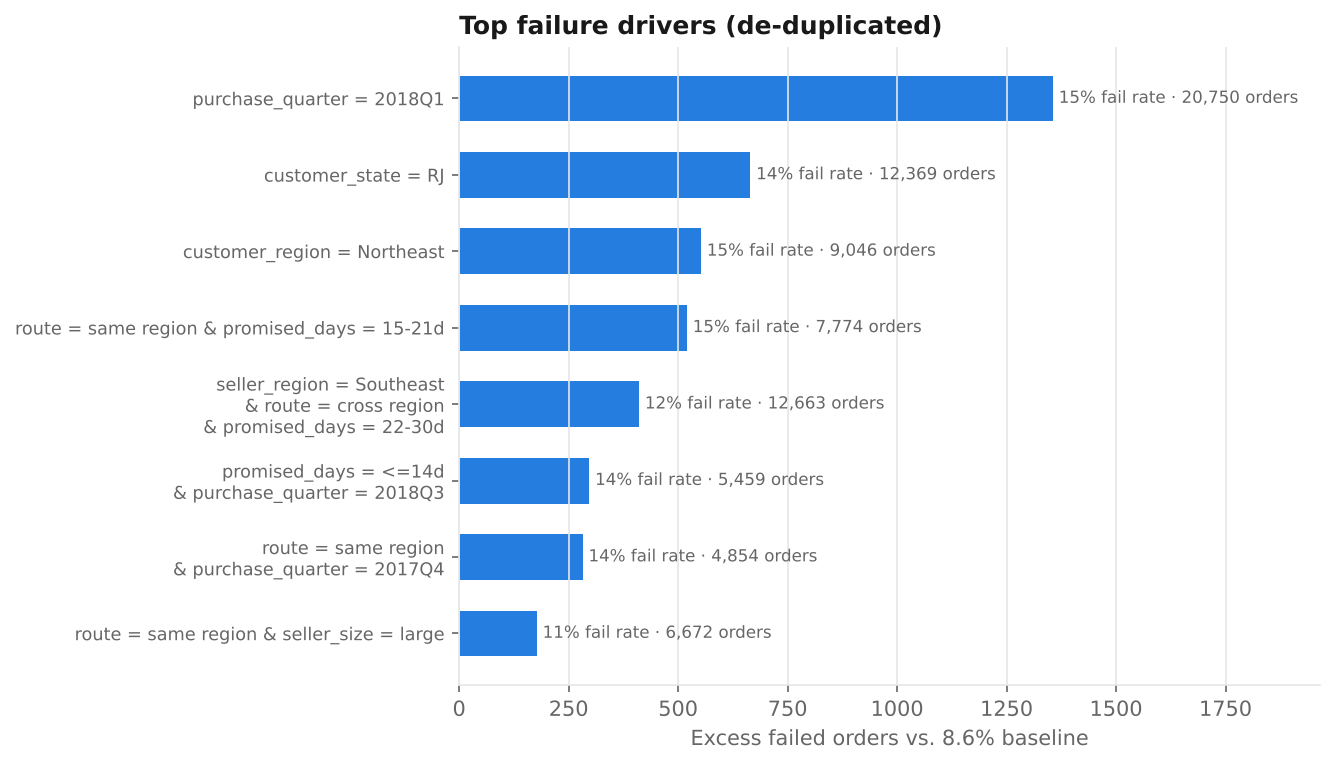

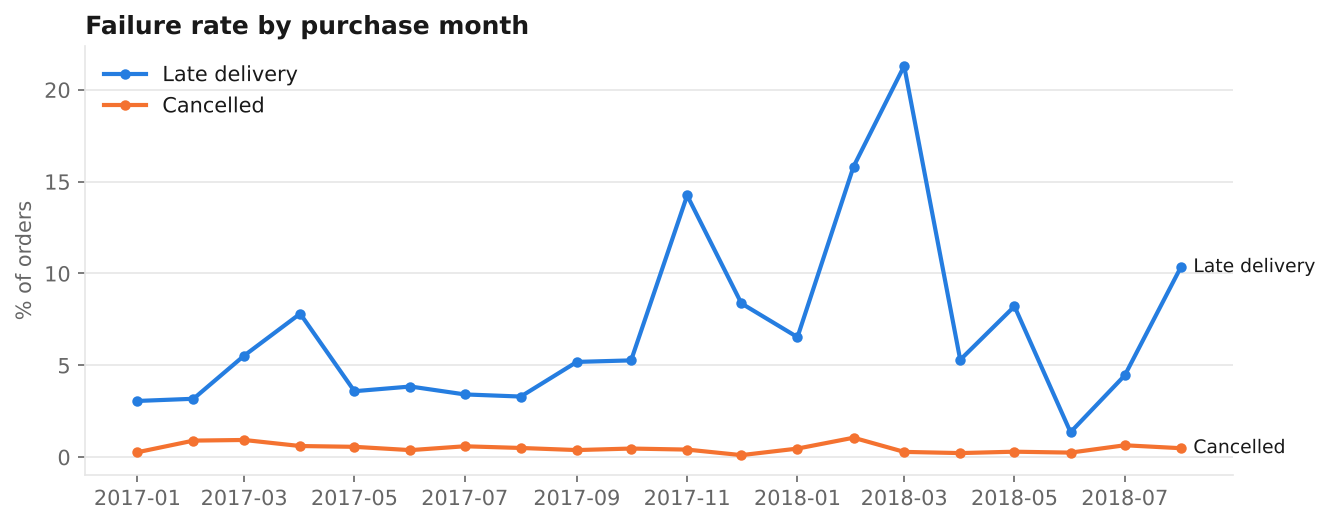

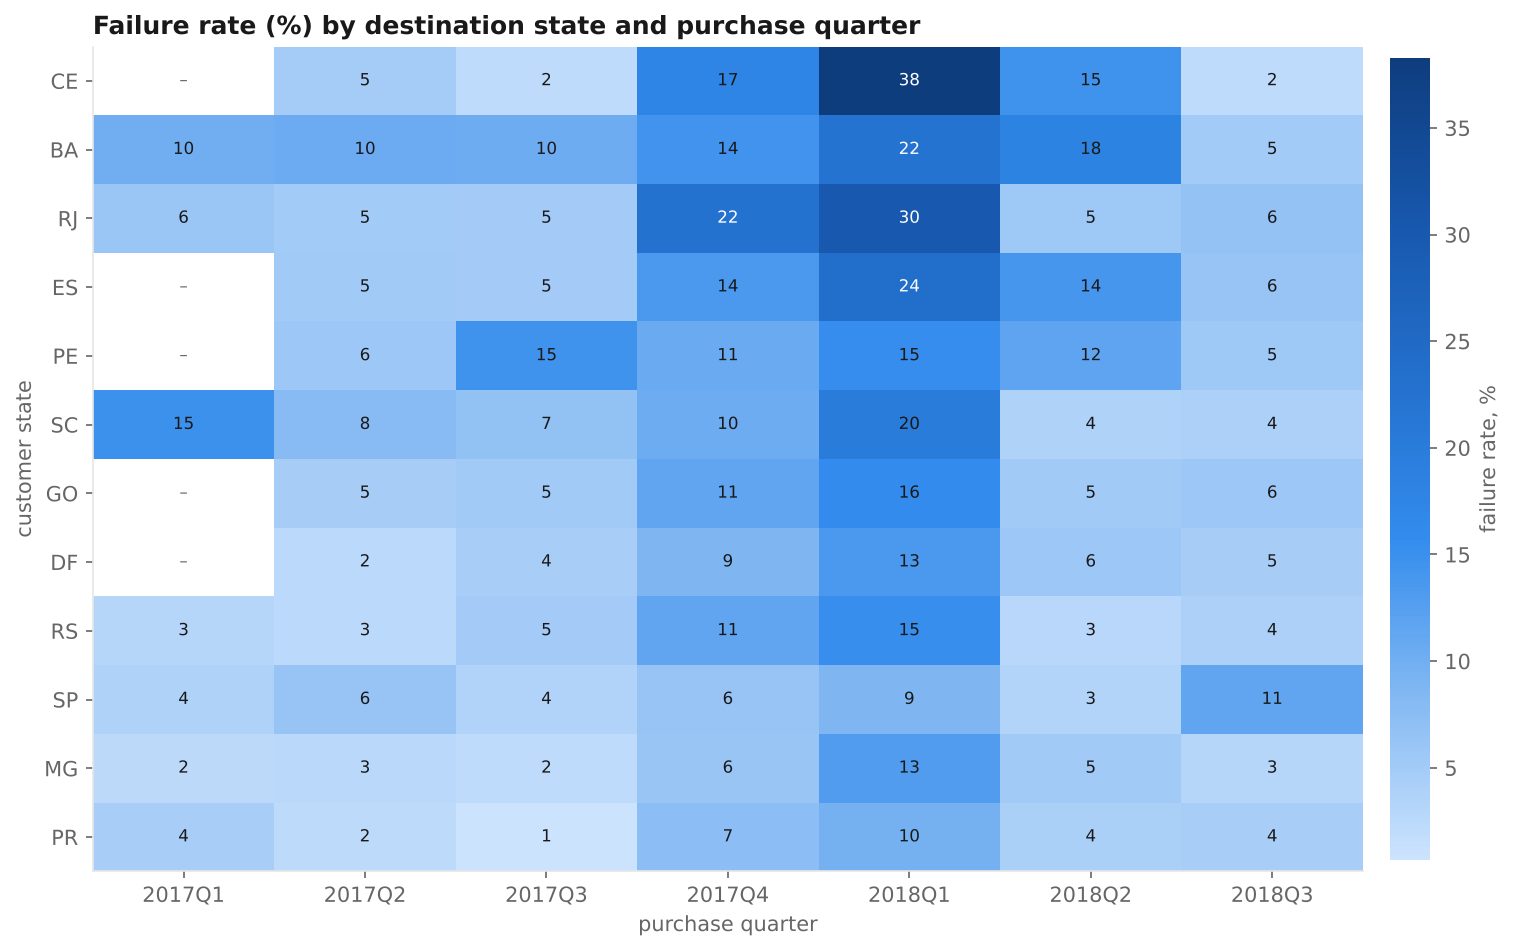

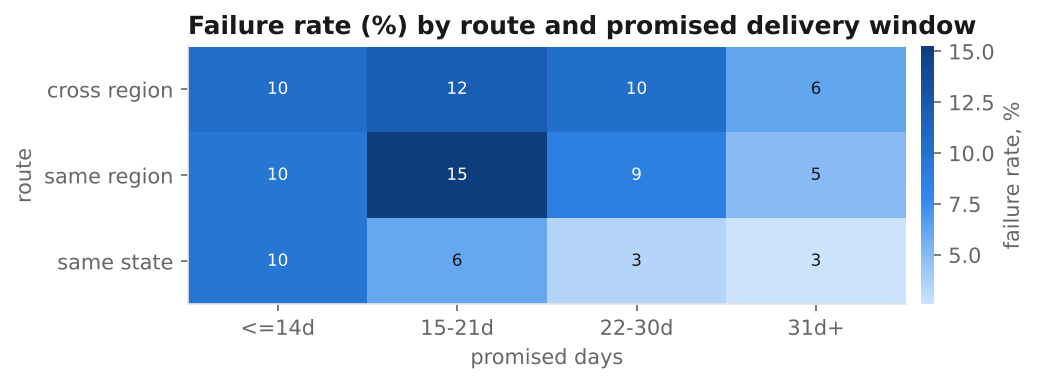

In [9]:
from IPython.display import Image, display
Path('figures').mkdir(exist_ok=True)
fig_drivers(drivers, base, Path('figures/top_drivers.png'));                display(Image('figures/top_drivers.png'))
fig_monthly(df, Path('figures/monthly.png'));                               display(Image('figures/monthly.png'))
fig_heatmap(df, 'customer_state', 'purchase_quarter', Path('figures/state_quarter.png'),
            'Failure rate (%) by destination state and purchase quarter', top_rows=12); display(Image('figures/state_quarter.png'))
fig_heatmap(df, 'route', 'promised_days', Path('figures/route_promise.png'),
            'Failure rate (%) by route and promised delivery window',
            col_order=['<=14d', '15-21d', '22-30d', '31d+']);                  display(Image('figures/route_promise.png'))

## Findings

Failures are a **timing and lane problem**, not a product or payment one.

| Finding | Evidence | Suggested action |
|---|---|---|
| **Network-wide peaks** | Late rate 14% in Nov 2017 and 21% in Mar 2018. Q1 2018 fails 15% (1.8× baseline), and 25 of 27 states are above baseline | Add a buffer to promised dates in peak weeks; plan capacity |
| **Rio de Janeiro and the Northeast** | RJ 14%, Northeast 15%, vs 7–8% for the South and Center-West | Review carrier performance on these destinations |
| **One lane is mis-promised** | Same-region orders promised 15–21 days fail 15%; RJ and ES buyers on that lane fail 22–24% | Recalibrate the delivery-date estimate for Southeast → RJ/ES |
| **No driver** in category, basket value, payment type, installments, weight, freight share, or item count | None passes the checks | Stop investigating product/checkout causes of late delivery |

The search function is generic: `bfs_search(df, attributes, target)` works on any 0/1 outcome, such as failed payments, churn, or crashes.